# Analyse des réservations d'hôtels

Les données utilisées sont le fichier nettoyé `data/processed/hotels_propre.csv` (voir `02_nettoyage.ipynb`). Chaque analyse répond à une des questions métier du notebook 01.

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
sns.set_theme(style="whitegrid")

hotels = pd.read_csv(
    "../data/processed/hotels_propre.csv",
    parse_dates=["arrival_date", "reservation_status_date"],
)

hotels["hotel"] = hotels["hotel"].map({
    "City Hotel": "Hôtel de ville",
    "Resort Hotel": "Hôtel de villégiature",
})
hotels["deposit_type"] = hotels["deposit_type"].map({
    "No Deposit": "Sans dépôt",
    "Refundable": "Dépôt remboursable",
    "Non Refund": "Dépôt non remboursable",
})
hotels

,hotel,is_canceled,lead_time,arrival_date_week_number,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,arrival_date
0,Hôtel de villégiature,0,7,27,0,1,1,0,0,BB,...,0,Sans dépôt,0,0,Transient,75.00,0,0,2015-07-02,2015-07-01
1,Hôtel de villégiature,0,13,27,0,1,1,0,0,BB,...,0,Sans dépôt,304,0,Transient,75.00,0,0,2015-07-02,2015-07-01
2,Hôtel de villégiature,0,14,27,0,2,2,0,0,BB,...,0,Sans dépôt,240,0,Transient,98.00,0,1,2015-07-03,2015-07-01
3,Hôtel de villégiature,0,0,27,0,2,2,0,0,BB,...,0,Sans dépôt,0,0,Transient,107.00,0,0,2015-07-03,2015-07-01
4,Hôtel de villégiature,0,9,27,0,2,2,0,0,FB,...,0,Sans dépôt,303,0,Transient,103.00,0,1,2015-07-03,2015-07-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86623,Hôtel de ville,0,23,35,2,5,2,0,0,BB,...,0,Sans dépôt,394,0,Transient,96.14,0,0,2017-09-06,2017-08-30
86624,Hôtel de ville,0,102,35,2,5,3,0,0,BB,...,0,Sans dépôt,9,0,Transient,225.43,0,2,2017-09-07,2017-08-31
86625,Hôtel de ville,0,34,35,2,5,2,0,0,BB,...,0,Sans dépôt,9,0,Transient,157.71,0,4,2017-09-07,2017-08-31
86626,Hôtel de ville,0,109,35,2,5,2,0,0,BB,...,0,Sans dépôt,89,0,Transient,104.40,0,0,2017-09-07,2017-08-31


In [2]:
taux_annulation_global = hotels["is_canceled"].mean() * 100
print(f"Taux d'annulation global : {taux_annulation_global:.1f} %")

Taux d'annulation global : 27.7 %


In [3]:
taux_par_hotel = hotels.groupby("hotel").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
taux_par_hotel["taux_annulation"] = (taux_par_hotel["taux_annulation"] * 100).round(1)
taux_par_hotel

,reservations,taux_annulation
hotel,,
Hôtel de ville,53038,30.2
Hôtel de villégiature,33590,23.7


In [4]:
taux_par_depot = hotels.groupby("deposit_type").agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
taux_par_depot["taux_annulation"] = (taux_par_depot["taux_annulation"] * 100).round(1)
taux_par_depot

,reservations,taux_annulation
deposit_type,,
Dépôt non remboursable,1037,94.7
Dépôt remboursable,107,24.3
Sans dépôt,85484,26.9


In [5]:
croisement_hotel_depot = (pd.pivot_table(
    hotels, values="is_canceled", index="hotel", columns="deposit_type", aggfunc="mean",
) * 100).round(1)
croisement_hotel_depot

deposit_type,Dépôt non remboursable,Dépôt remboursable,Sans dépôt
hotel,,,
Hôtel de ville,97.2,66.7,29.1
Hôtel de villégiature,83.9,17.4,23.4


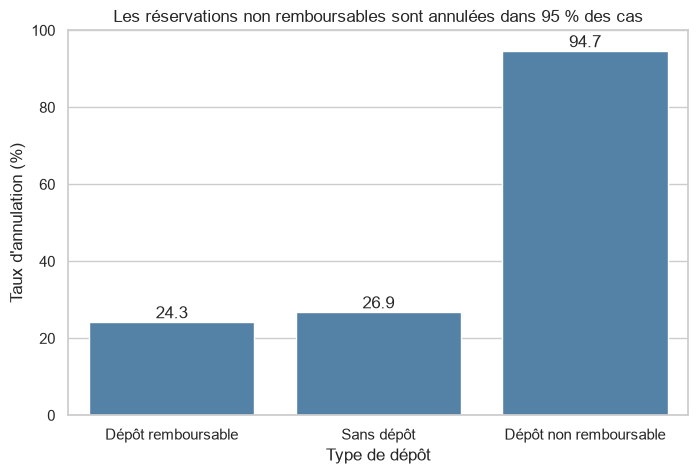

In [6]:
taux_depot_trie = (hotels.groupby("deposit_type")["is_canceled"].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=taux_depot_trie.index, y=taux_depot_trie.values, color="steelblue", ax=ax)
ax.set_title("Les réservations non remboursables sont annulées dans 95 % des cas")
ax.set_xlabel("Type de dépôt")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_1_annulation_depot.png", dpi=150, bbox_inches="tight")
plt.show()

**Type de graphique : barres.** On compare un taux entre trois catégories de dépôt, triées de la plus basse à la plus haute.

**Réponse à la question 1 :** 27.7 % des réservations sont annulées. L'hôtel de ville annule davantage (30.2 %) que l'hôtel de villégiature (23.7 %). Le type de dépôt pèse encore plus : 94.7 % des réservations à dépôt non remboursable sont annulées, contre 26.9 % sans dépôt. Ce résultat est contre-intuitif et à interpréter avec prudence : ces réservations ne représentent que 1037 lignes (1,2 % du total) et le jeu de données ne dit pas pourquoi.

In [8]:
hotels["tranche_delai"] = pd.cut(
    hotels["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, 1000],
    labels=["0 à 7 jours", "8 à 30 jours", "31 à 90 jours",
            "91 à 180 jours", "181 à 365 jours", "plus de 365 jours"],
)

annulation_par_delai = hotels.groupby("tranche_delai", observed=True).agg(
    reservations=("is_canceled", "size"),
    taux_annulation=("is_canceled", "mean"),
)
annulation_par_delai["taux_annulation"] = (annulation_par_delai["taux_annulation"] * 100).round(1)
annulation_par_delai

,reservations,taux_annulation
tranche_delai,,
0 à 7 jours,17851,8.5
8 à 30 jours,16231,25.5
31 à 90 jours,22633,32.1
91 à 180 jours,18188,35.1
181 à 365 jours,11164,39.8
plus de 365 jours,561,41.0


In [9]:
hotels.groupby("is_canceled")["lead_time"].median()

is_canceled
0    38.0
1    80.0
Name: lead_time, dtype: float64

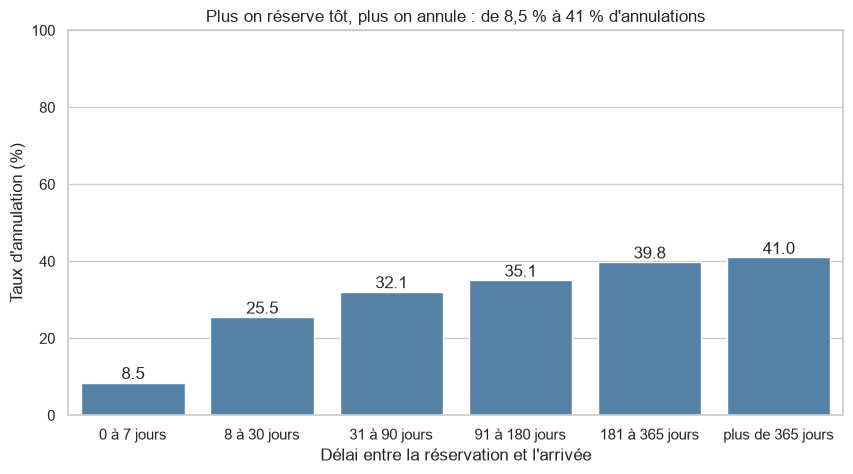

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=annulation_par_delai.index.astype(str),
    y=annulation_par_delai["taux_annulation"],
    color="steelblue", ax=ax,
)
ax.set_title("Plus on réserve tôt, plus on annule : de 8,5 % à 41 % d'annulations")
ax.set_xlabel("Délai entre la réservation et l'arrivée")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f")
fig.savefig("../figures/graphique_2_delai.png", dpi=150, bbox_inches="tight")
plt.show()

**Type de graphique : barres.** Les tranches de délai ont un ordre naturel (du plus court au plus long), qui est aussi l'ordre croissant des taux.

**Réponse à la question 2 :** Oui, le délai influence les annulations. Seulement 8.5 % des réservations faites moins d'une semaine avant l'arrivée sont annulées, contre 39.8 % à 41 % pour celles faites plus de six mois à l'avance. Le délai médian est de 38 jours pour les réservations maintenues et de 80 jours pour les annulées. Cette analyse montre un lien, pas une cause.

In [11]:
arrivees_par_mois = hotels.set_index("arrival_date").resample("MS").size()
arrivees_par_mois.name = "arrivees"
arrivees_par_mois.to_frame()

,arrivees
arrival_date,
2015-07-01,1652
2015-08-01,2428
2015-09-01,2823
2015-10-01,2661
2015-11-01,1636
2015-12-01,1940
2016-01-01,1823
2016-02-01,2771
2016-03-01,3791


In [12]:
noms_mois = ["janvier", "février", "mars", "avril", "mai", "juin",
             "juillet", "août", "septembre", "octobre", "novembre", "décembre"]

classement_2016 = arrivees_par_mois.loc["2016"].sort_values(ascending=False)
classement_2016.index = [noms_mois[date.month - 1] for date in classement_2016.index]
classement_2016

août         4394
octobre      4180
septembre    3835
juillet      3818
mars         3791
avril        3741
mai          3739
juin         3487
novembre     3278
décembre     3104
février      2771
janvier      1823
Name: arrivees, dtype: int64

In [13]:
print(f"Mois le plus chargé : {arrivees_par_mois.idxmax():%Y-%m} ({arrivees_par_mois.max()} arrivées)")
print(f"Mois le plus calme : {arrivees_par_mois.idxmin():%Y-%m} ({arrivees_par_mois.min()} arrivées)")

Mois le plus chargé : 2017-05 (4556 arrivées)
Mois le plus calme : 2015-11 (1636 arrivées)


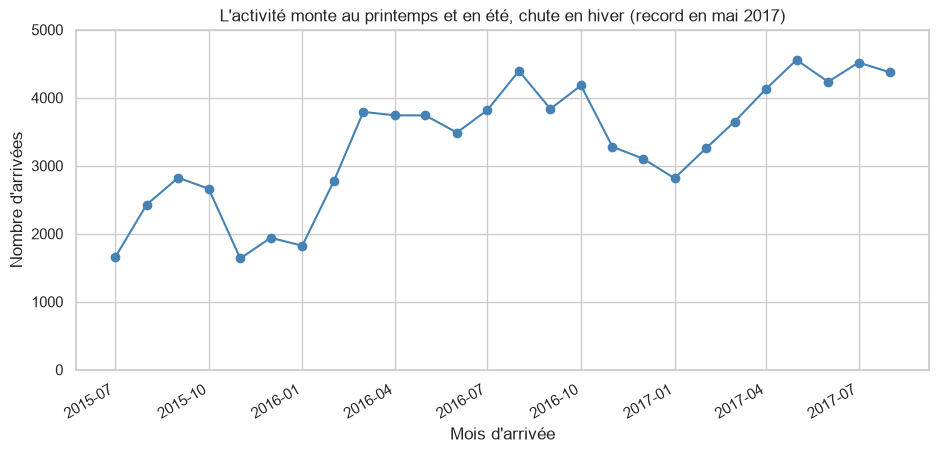

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(arrivees_par_mois.index, arrivees_par_mois.values, marker="o", color="steelblue")
ax.set_title("L'activité monte au printemps et en été, chute en hiver (record en mai 2017)")
ax.set_xlabel("Mois d'arrivée")
ax.set_ylabel("Nombre d'arrivées")
ax.set_ylim(0, 5000)
fig.autofmt_xdate()
fig.savefig("../figures/graphique_3_arrivees_par_mois.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
hotels_payants = hotels[hotels["adr"] > 0].copy()
hotels_payants["mois_arrivee"] = hotels_payants["arrival_date"].dt.month

saisons = {12: "Hiver", 1: "Hiver", 2: "Hiver",
           3: "Printemps", 4: "Printemps", 5: "Printemps",
           6: "Été", 7: "Été", 8: "Été",
           9: "Automne", 10: "Automne", 11: "Automne"}
hotels_payants["saison"] = hotels_payants["mois_arrivee"].map(saisons)
ordre_saisons = ["Hiver", "Printemps", "Été", "Automne"]

print(f"Séjours avec un prix : {len(hotels_payants)} sur {len(hotels)}")

Séjours avec un prix : 85576 sur 86628


In [16]:
prix_par_saison = hotels_payants.groupby("saison")["adr"].agg(
    sejours="size", prix_moyen="mean",
).round(1).loc[ordre_saisons]
prix_par_saison

,sejours,prix_moyen
saison,,
Hiver,15464,77.7
Printemps,23358,100.8
Été,28647,139.3
Automne,18107,96.0


In [17]:
prix_hotel_saison = pd.pivot_table(
    hotels_payants, values="adr", index="hotel", columns="saison", aggfunc="mean",
)[ordre_saisons].round(1)
prix_hotel_saison

saison,Hiver,Printemps,Été,Automne
hotel,,,,
Hôtel de ville,91.5,115.3,125.1,110.0
Hôtel de villégiature,58.1,74.4,160.3,74.0


In [18]:
prix_par_mois = hotels_payants.groupby("mois_arrivee")["adr"].mean().round(1)
prix_par_mois

mois_arrivee
1      71.9
2      76.5
3      82.5
4     105.2
5     113.1
6     121.5
7     137.7
8     153.0
9     114.7
10     92.9
11     74.9
12     84.6
Name: adr, dtype: float64

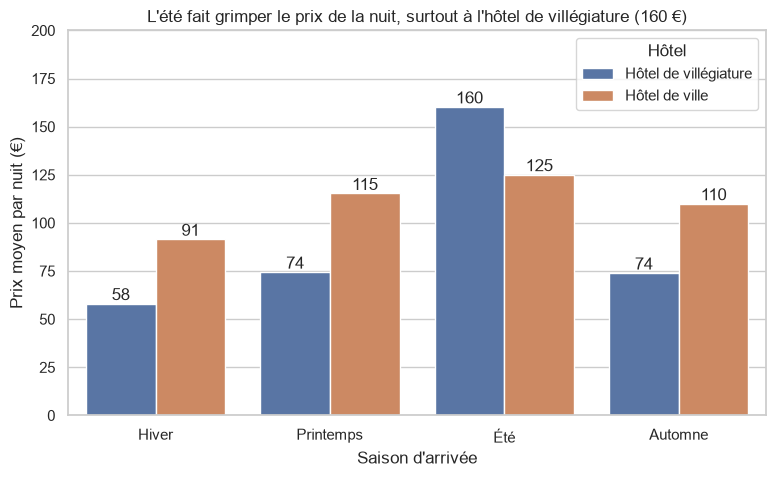

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=hotels_payants, x="saison", y="adr", hue="hotel",
    order=ordre_saisons, errorbar=None, ax=ax,
)
ax.set_title("L'été fait grimper le prix de la nuit, surtout à l'hôtel de villégiature (160 €)")
ax.set_xlabel("Saison d'arrivée")
ax.set_ylabel("Prix moyen par nuit (€)")
ax.set_ylim(0, 200)
ax.legend(title="Hôtel")
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.0f")
fig.savefig("../figures/graphique_4_prix_par_saison.png", dpi=150, bbox_inches="tight")
plt.show()

**Graphique 3 : courbe.** Elle convient à une évolution dans le temps, mois après mois.
**Graphique 4 : barres groupées.** Elles comparent un prix moyen entre quatre saisons, avec une couleur par hôtel (la couleur porte un sens). Les saisons suivent l'ordre du calendrier plutôt qu'un tri par valeur.

**Réponse à la question 3 :** Le printemps et l'été sont les périodes les plus chargées, l'hiver la plus calme. Sur 2016, la seule année complète, août est le mois le plus chargé (4394 arrivées) et janvier le plus calme (1823). Le record de la série est mai 2017 (4556) et le creux novembre 2015 (1636). Le prix moyen par nuit suit la même saisonnalité : 77.7 en hiver, 100.8 au printemps, 139.3 en été et 96.0 en automne. L'effet est bien plus fort à l'hôtel de villégiature (58.1 en hiver, 160.3 en été, soit presque trois fois plus) qu'à l'hôtel de ville (91.5 en hiver, 125.1 en été). Le mois le plus cher est août (153.0), le moins cher janvier (71.9).

**Limites :** le jeu de données ne précise pas la devise (supposée en euros) et le volume d'arrivées est plus faible au début de la période (été 2015), ce qui rend les comparaisons d'une année à l'autre moins fiables. Les 1052 séjours à prix 0 sont exclus des moyennes de prix.